# 01. Exploratory data analysis

**The task.** The original Excel file in `data/raw/` is an anonymized accounts payable ledger: 5,899 invoice lines, seven input columns (`Col1` to `Col7`) and a label, `ClassificationLabel`. The goal is a model that suggests the label for new invoice lines. This notebook studies the data before any modeling. It covers what each column holds, how the classes are distributed, where values are missing or extreme, which inputs carry information about the label, and why duplicate rows matter for honest evaluation.

**The columns.** The file names them only `Col1` to `Col7`; the roles below are inferred from the values (section 1).

| Column | Role | Example |
|---|---|---|
| Col1 | Vendor | `Word16 Word17 Word18 Word7` |
| Col2 | Invoice number (identifier) | `10719`, `4.80P+11` |
| Col3 | Amount | `1680` |
| Col4 | Line description | `Word61` |
| Col5 | Posting date (month end) | `2018-08-31` |
| Col6 | GL account | `Word563 Word575` |
| Col7 | Document flag | `NoDoc`, `Doc1` |

Words such as `Word563` are anonymized tokens. Their meaning is hidden, but the same token always stands for the same word.

**Which rows this notebook uses.** 10% of the rows (590) were set aside as a **holdout** before any analysis. They are used once, at the very end, to check the final model on data it has never seen (notebook 03, section 11). Everything here that involves the label uses only the remaining **training portion (5,309 rows)**. Checks that never look at the label (column formats, label spellings) use the full file.

**How to read it.** Each section shows a table or chart, then a **Takeaway** stating what was learned and what it changed in the model. All numbers come from report files written by `python -m ledgerclf eda` (folder `reports/eda/`). The notebook only loads and plots them, so the dashboard shows the same figures. To rerun: `python -m ledgerclf eda`, then `python tools/run_notebooks.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from _style import CLASS_COLORS, INK_SECONDARY, SEQUENTIAL, apply_style, class_colors, report
from IPython.display import display

apply_style()
pd.set_option("display.max_colwidth", 60)
CLASSES = list(CLASS_COLORS)

## 1. What is in the file

Seven inputs and one label. Column roles are working hypotheses from value patterns; the file itself names only `Col1` to `Col7`.

In [2]:
schema = report("eda/schema_summary.json")
pd.DataFrame(schema["column_details"]).T[["inferred_role", "unique", "missing", "python_types"]]

,inferred_role,unique,missing,python_types
ClassificationLabel,Target,11,0,{'str': 5899}
Col1,Vendor name,313,0,{'str': 5899}
Col2,Invoice number,4818,0,"{'float': 3, 'int': 3526, 'str': 2370}"
Col3,Amount,2397,0,"{'float': 2383, 'int': 3516}"
Col4,Line description,2032,153,{'str': 5746}
Col5,Posting period,17,0,{'datetime': 5899}
Col6,GL account name,196,0,{'str': 5899}
Col7,Document flag,4,0,{'str': 5899}


**Takeaway.** 5,899 rows. Col1 (vendor), Col4 (line description), and Col6 (GL account) are anonymized text such as `Word563 Word564`. Col3 is an amount, Col5 a posting date, Col7 a 4-value document flag. Col2 mixes integers, strings, and floats, a first sign that it is an identifier, not a feature. Only Col4 has missing values (153 rows in the full file).

## 2. The label: eleven spellings, six classes

The raw label column holds typos and spacing variants of six categories. One fixed rule maps every spelling to its category: lowercase, remove spaces and underscores, fix the typo `categry`, and read the digit. The same rule runs on any labeled file a user uploads.

In [3]:
report("eda/raw_label_mapping.csv")

,raw_label,canonical_label,rows
0,Category_1,Category_1,5204
1,category_1,Category_1,11
2,Category2,Category_2,4
3,Category_2,Category_2,627
4,Category 3,Category_3,10
5,Category _3,Category_3,1
6,Category_3,Category_3,12
7,Category4,Category_4,16
8,Category 5,Category_5,2
9,Category_6,Category_6,2


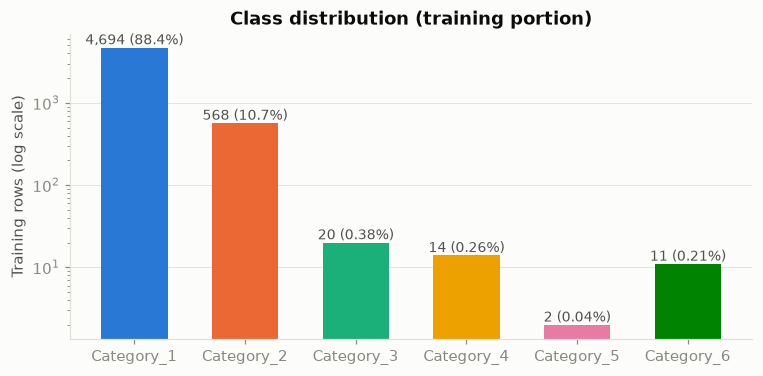

,class,rows,share
0,Category_1,4694,0.884159
1,Category_2,568,0.106988
2,Category_3,20,0.003767
3,Category_4,14,0.002637
4,Category_5,2,0.000377
5,Category_6,11,0.002072


In [4]:
dist = report("eda/class_distribution.csv")
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(dist["class"], dist["rows"], color=class_colors(dist["class"]), width=0.6)
ax.set_yscale("log")
ax.set_ylabel("Training rows (log scale)")
ax.set_title("Class distribution (training portion)")
for bar, rows, share in zip(bars, dist["rows"], dist["share"], strict=True):
    label = f"{share:.2%}" if share < 0.01 else f"{share:.1%}"
    ax.annotate(
        f"{rows:,} ({label})",
        (bar.get_x() + bar.get_width() / 2, rows),
        ha="center",
        va="bottom",
        fontsize=9,
        color=INK_SECONDARY,
    )
ax.grid(axis="x", visible=False)
plt.show()
dist

**Takeaway.** Extreme imbalance: Category_1 is 88.4% of training rows, Category_2 10.7%, and four rare classes share 47 rows (Category_3: 20, Category_4: 14, Category_6: 11, Category_5: 2). Consequences for the build:

- A model that always answers Category_1 is already 88.4% accurate, so accuracy alone hides failure on the rare classes. Every result is therefore also reported as **macro F1**: the F1 score (the balance of precision and recall) computed for each class and then averaged, so every class counts equally. It covers the five classes with 11 or more rows (`macro_f1_5`).
- Category_5 has only 2 rows, and no model can learn a class from 2 examples. It stays in the model, but it is reported separately instead of dragging the macro F1 to noise.
- With 11 to 20 rows per rare class, a single row moves rare-class recall by 5 to 9 points, so every model comparison is repeated with 3 different random seeds.

## 3. Missing values

In [5]:
report("eda/missing_values.csv")

,column,missing_rows,missing_share,missing_Category_1,missing_Category_2,missing_Category_3,missing_Category_4,missing_Category_5,missing_Category_6
0,Col1,0,0.000000,0,0,0,0,0,0
1,Col2,0,0.000000,0,0,0,0,0,0
2,Col3,0,0.000000,0,0,0,0,0,0
3,Col4,145,0.027312,134,11,0,0,0,0
4,Col5,0,0.000000,0,0,0,0,0,0
5,Col6,0,0.000000,0,0,0,0,0,0
6,Col7,0,0.000000,0,0,0,0,0,0


**Takeaway.** Only Col4 is ever missing (145 training rows, 2.7%), all in Category_1 or Category_2. A missing description becomes its own token (`__missing__`) instead of a reason to drop the row, and the prediction service never drops a row: every uploaded line gets a prediction. Uploaded files can have gaps in any column, so missing amounts and dates are filled with the training median and the row is flagged for the reviewer.

## 4. Col2, the invoice number: an identifier, not a feature

In [6]:
display(report("eda/col2_type_mix.csv"))
report("eda/col2_patterns.csv").head(10)

,category,rows
0,int,3526
1,str,2370
2,float,3
3,scientific-style text (subset of str),326


,pattern,rows,example
0,9999,1189,4411
1,99999,1149,10719
2,999999,676,684417
3,9.99A+99,326,4.80Z+11
4,AA9999,326,WE1243
5,99999999,242,44912133
6,AA999,220,RL357
7,AAA99999,146,FKM52390
8,999999-99999,116,201811-00046
9,AA99999999,98,IK20170536


**Takeaway.** 4,818 distinct values in 5,899 rows, three Python types, and 326 values that are Excel scientific notation with a letter swapped in for `E` (`4.80P+11`). Identical rows often differ only in this column. A raw invoice number would let a model memorize IDs that never recur. Format features (length, letters, digit share) add less than one fold's standard deviation in the benchmark (notebook 03, section 3). **Col2 is dropped from the model and kept for display.**

## 5. Col3, the amount: heavy tails and meaningful signs

In [7]:
display(report("eda/amount_summary.csv"))
report("eda/amount_by_class.csv")

,statistic,value
0,rows,5.309000e+03
1,missing,0.000000e+00
2,min,-2.691116e+05
3,p25,3.600000e+02
4,median,1.080000e+03
5,mean,1.342603e+05
6,p75,4.290000e+03
7,max,8.799524e+06
8,negative_rows,6.300000e+01
9,zero_rows,2.000000e+00


,class,count,median,mean,min,max
0,Category_1,4694,1158.00,151215.501419,-269111.58,8799523.59
1,Category_2,568,581.39,4714.656708,7.54,275188.08
2,Category_3,20,1680.00,6510.990000,703.55,51073.00
3,Category_4,14,7436.58,11191.372143,1500.00,44543.80
4,Category_5,2,-2718.26,-2718.260000,-4645.86,-790.66
5,Category_6,11,1680.00,2075.302727,439.85,9820.00


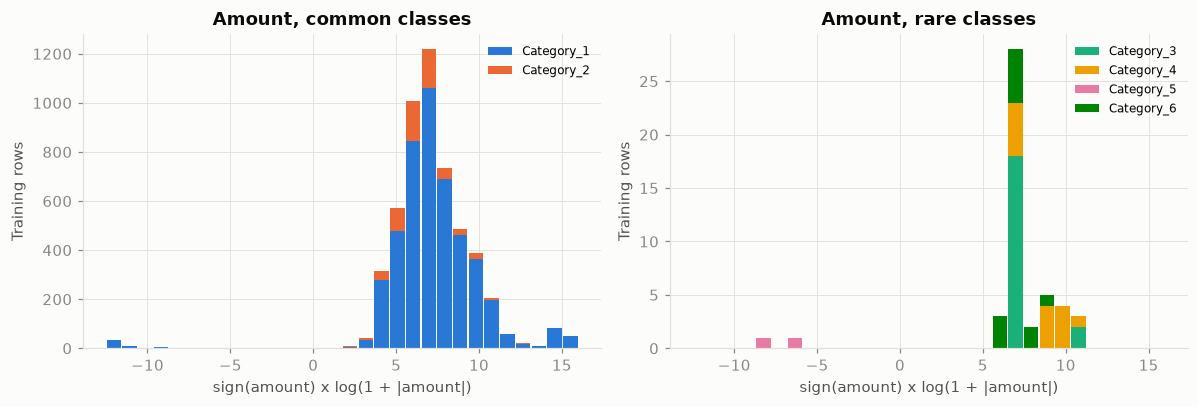

In [8]:
hist = report("eda/amount_histogram.csv")
centers = (hist["bin_left"] + hist["bin_right"]) / 2
width = (hist["bin_right"] - hist["bin_left"]).iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
groups = [["Category_1", "Category_2"], ["Category_3", "Category_4", "Category_5", "Category_6"]]
for ax, group in zip(axes, groups, strict=True):
    bottom = np.zeros(len(hist))
    for cls in group:
        ax.bar(
            centers,
            hist[cls],
            bottom=bottom,
            width=width * 0.92,
            color=CLASS_COLORS[cls],
            label=cls,
        )
        bottom += hist[cls]
    ax.set_xlabel("sign(amount) x log(1 + |amount|)")
    ax.set_ylabel("Training rows")
    ax.legend(fontsize=8)
axes[0].set_title("Amount, common classes")
axes[1].set_title("Amount, rare classes")
plt.tight_layout()
plt.show()

In [9]:
outliers = report("eda/amount_outliers.csv")
print(f"{len(outliers)} rows outside the 1.5 x IQR fences of the signed-log amount")
outliers.groupby(["side", "class"]).size().rename("rows").reset_index()

235 rows outside the 1.5 x IQR fences of the signed-log amount


,side,class,rows
0,high,Category_1,163
1,high,Category_2,4
2,low,Category_1,64
3,low,Category_2,2
4,low,Category_5,2


**Takeaway.** Amounts run from -269,112 to 8.8 million with a median of 1,080 (skewness 8.4). A signed log (`sign(x) * log1p(|x|)`) keeps credits negative and compresses the tail.

- **Outliers are kept.** 235 rows fall outside the IQR fences on the signed-log scale; 227 are ordinary Category_1 invoices, large and small. They look like real ledger values, and dropping them would teach the model nothing about large invoices. The prediction service must score every row anyway.
- **The sign matters.** Both Category_5 rows are negative amounts from one vendor; the negative flag is the only Category_5 signal.
- **Round amounts recur in rare classes** (1,680 in Category_3, Category_4, and Category_6; 1,500 in Category_3 and Category_4), so a round-amount flag joins the features.

## 6. Col5, the posting period

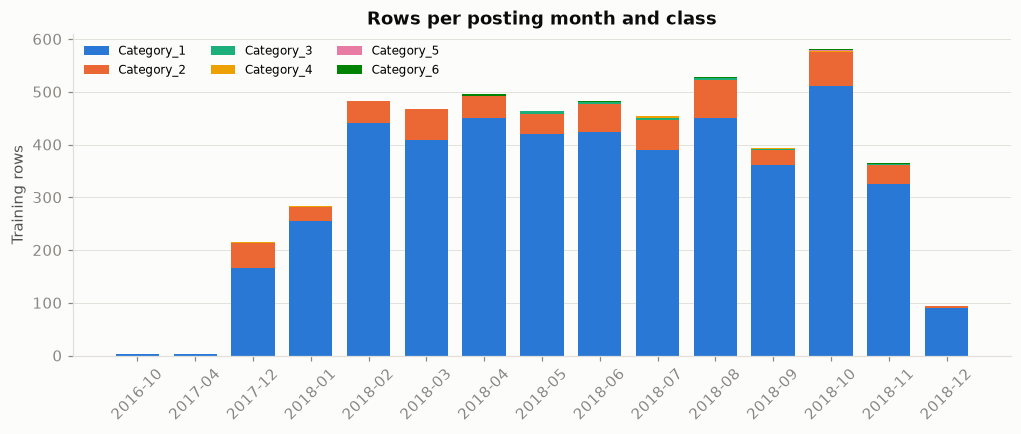

,day,rows
0,1,1709
1,30,1480
2,31,2120


,Category_1,Category_2,Category_3,Category_4,Category_5,Category_6,total
period,,,,,,,
2016-10,3,0,0,0,0,0,3
2017-04,2,0,0,0,0,0,2
2017-12,166,47,0,2,0,0,215
2018-01,255,26,0,2,0,0,283
2018-02,440,42,0,1,0,0,483
2018-03,408,59,0,0,0,0,467
2018-04,450,41,0,1,0,3,495
2018-05,419,38,6,0,0,1,464
2018-06,423,54,3,1,0,2,483


In [10]:
periods = report("eda/period_by_class.csv").set_index("period")
fig, ax = plt.subplots(figsize=(11, 3.8))
bottom = np.zeros(len(periods))
for cls in CLASSES:
    ax.bar(
        periods.index, periods[cls], bottom=bottom, color=CLASS_COLORS[cls], label=cls, width=0.75
    )
    bottom += periods[cls].to_numpy()
ax.set_ylabel("Training rows")
ax.set_title("Rows per posting month and class")
ax.tick_params(axis="x", rotation=45)
ax.legend(ncol=3, fontsize=8)
ax.grid(axis="x", visible=False)
plt.show()
display(report("eda/day_of_month.csv"))
periods

**Takeaway.** Dates fall only on the 1st, 30th, or 31st of a month, so Col5 is a **monthly posting period**, not a calendar date. Almost everything is 2017-12 to 2018-12; 2016-10 and 2017-04 hold 5 rows. Rare classes cluster in time (Category_3 from 2018-05, Category_4 mostly 2017-12 to 2018-02 and 2018-07, both Category_5 rows in 2018-10).

The model uses a **period index** (`year * 12 + month`) clipped to the training range, because a linear model would otherwise extrapolate wildly for a date such as 2030. The concentration in 2018 also motivates an **out-of-time check**: train on periods up to 2018-09, then test on 2018-10 to 2018-12, the way the model would be used on future months.

## 7. Col7, the document flag

In [11]:
report("eda/col7_by_class.csv")

,Col7,Category_1,Category_2,Category_3,Category_4,Category_5,Category_6,total
0,Doc1,968,36,0,0,1,0,1005
1,Doc2,30,0,0,0,0,0,30
2,Doc3,83,15,0,10,0,0,108
3,NoDoc,3613,517,20,4,1,11,4166


**Takeaway.** 78% of rows are `NoDoc`. `Doc3` holds 10 of the 14 training Category_4 rows. Once the text columns are present, Col7 adds almost nothing on its own: its information overlaps the account (see Cramer's V below), and dropping it changes accuracy by 0.0001 in the benchmark ablation. It is cheap and kept.

## 8. The text columns: vendor, description, account

In [12]:
report("eda/text_cardinality.csv")

,column,unique_values,missing_rows,token_vocabulary,mean_tokens,max_tokens,values_seen_once,in_sample_majority_purity
0,Col1,301,0,536,3.961198,10,108,0.932567
1,Col4,1881,145,1490,2.825910,9,1245,0.985873
2,Col6,192,0,274,3.759277,7,55,0.923526


In [13]:
for column in ("col1", "col6", "col4"):
    print(f"Top values of {column.upper()}")
    display(report(f"eda/top_values_{column}.csv").head(8))

Top values of COL1


,value,Category_1,Category_2,Category_3,Category_4,Category_5,Category_6,total
0,Word16 Word17 Word18 Word7,1131,5,0,0,0,0,1136
1,Word8 Word9 Word10 Word11 Word5,288,0,0,0,0,0,288
2,Word30 Word31,246,0,0,0,0,0,246
3,Word85 Word86 Word87 Word5 Word88 Word16 Word17 Word3 Word7,92,90,0,0,0,0,182
4,Word19 Word20 Word21 Word22 Word23 Word5,12,168,0,0,0,0,180
5,Word16 Word17 Word3 Word7,98,81,0,0,0,0,179
6,Word33 Word34 Word35 Word7,157,0,0,0,0,0,157
7,Word42 Word43 Word5,135,12,0,0,0,0,147


Top values of COL6


,value,Category_1,Category_2,Category_3,Category_4,Category_5,Category_6,total
0,Word563 Word564 Word9 Word26,1966,5,0,0,0,0,1971
1,Word563 Word580 Word581 Word232,325,128,0,0,0,0,453
2,Word563 Word366 Word562,272,120,0,0,0,0,392
3,Word563 Word575,28,171,0,0,0,0,199
4,Word567 Word568 Word569 Word570,163,0,0,0,0,0,163
5,Word563 Word121 Word579,156,0,0,0,0,0,156
6,Word563 Word366 Word56 Word4,142,0,0,0,0,0,142
7,Word563 Word132 Word610,118,10,0,0,0,0,128


Top values of COL4


,value,Category_1,Category_2,Category_3,Category_4,Category_5,Category_6,total
0,Word61,193,0,0,0,0,0,193
1,Word562,134,33,0,0,0,0,167
2,__missing__,134,11,0,0,0,0,145
3,Word783 Word784 Word785,140,0,0,0,0,0,140
4,Word826 Word780,95,0,0,0,0,0,95
5,Word797 Word190,71,1,0,0,0,0,72
6,Word123 Word190,69,1,0,0,0,0,70
7,Word330 Word99 Word26,69,0,0,0,0,0,69


In [14]:
report("eda/token_overlap.csv")

,column_a,column_b,shared_tokens,example
0,Col1,Col4,108,Word100
1,Col1,Col6,62,Word107
2,Col4,Col6,139,Word107


**Takeaway.**

- **Vendor (Col1)** has 301 distinct values; the top vendor alone covers 1,136 rows. Some vendors split across classes (`Word85 ... Word3 Word7`: 92 Category_1, 90 Category_2), so the vendor alone is not enough.
- **Account (Col6)** separates many of those splits; `Word563 Word575` is 86% Category_2.
- **Description (Col4)** is the most varied column (1,881 values, 1,245 seen once). Dropping its words costs 1.7 points of accuracy and 0.08 macro F1 in the benchmark ablation, the largest loss of any input.
- The same token appears in several columns with different roles (Col1 and Col4 share 108 tokens). So **each text column gets its own TF-IDF vectorizer** (word counts weighted by how rare each word is), plus one-hot indicators for whole recurring values and for vendor-account pairs.
- Tokens are anonymized (`Word563`), so pretrained language models or word embeddings have no meaning to draw on. Models that learn token identities directly from this data are the right tool.

## 9. Correlations: Cramer's V and mutual information

Bias-corrected Cramer's V (0 = no association, 1 = one variable determines the other) among categorical views of the inputs and the label. The amount enters as a decile, the period as a month.

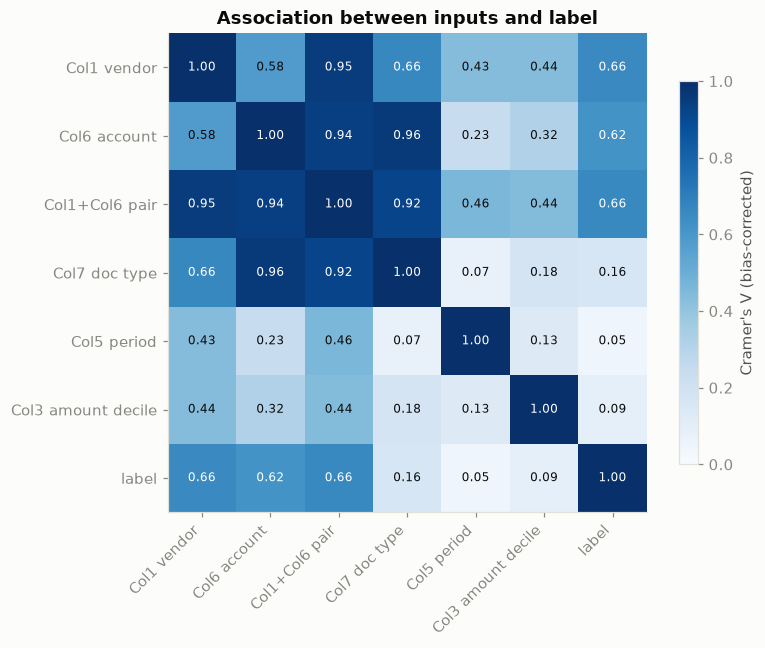

In [15]:
cv = report("eda/cramers_v.csv").set_index("variable")
fig, ax = plt.subplots(figsize=(7.5, 6))
image = ax.imshow(cv.to_numpy(), cmap=SEQUENTIAL, vmin=0, vmax=1)
ax.set_xticks(range(len(cv)), cv.columns, rotation=45, ha="right")
ax.set_yticks(range(len(cv)), cv.index)
for i in range(len(cv)):
    for j in range(len(cv)):
        value = cv.iloc[i, j]
        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if value > 0.6 else "#0b0b0b",
        )
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.8, label="Cramer's V (bias-corrected)")
ax.set_title("Association between inputs and label")
plt.tight_layout()
plt.show()

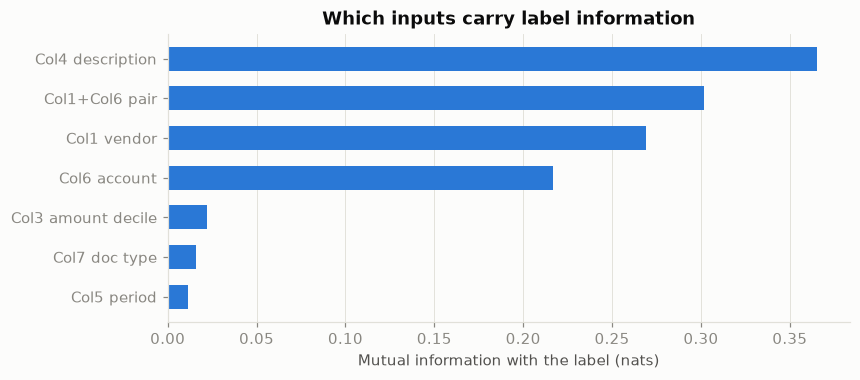

,variable,categories,mutual_information_nats,normalized_mutual_information
0,Col4 description,1882,0.365401,0.106108
1,Col1+Col6 pair,785,0.301720,0.114842
2,Col1 vendor,301,0.268899,0.122704
3,Col6 account,192,0.216638,0.126762
4,Col3 amount decile,10,0.022131,0.016375
5,Col7 doc type,4,0.016201,0.031946
6,Col5 period,15,0.011406,0.007845


In [16]:
mi = report("eda/mutual_information.csv")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(mi["variable"][::-1], mi["mutual_information_nats"][::-1], color="#2a78d6", height=0.6)
ax.set_xlabel("Mutual information with the label (nats)")
ax.set_title("Which inputs carry label information")
ax.grid(axis="y", visible=False)
plt.show()
mi

**Takeaway.**

- **The text columns carry the label.** Vendor, account, and vendor-account pair each reach Cramer's V of about 0.62 to 0.66 with the label; description has the highest mutual information (0.37 nats). Amount decile (0.09), document flag (0.16), and period (0.05) are weak on their own.
- **Inputs overlap heavily.** The pair is almost determined by vendor (0.95) and account (0.94), and the document flag by the account (0.96). Redundancy is fine for regularized models but means ablations, not raw correlations, decide what to keep.
- High-cardinality variables inflate mutual information (Col4 has 1,882 categories), so the normalized column and the grouped CV results are the honest check.
- Weak marginal signals still matter for rare classes: the amount sign is the only Category_5 signal and the period separates Category_3, Category_4, and Category_6 within one vendor.

## 10. Duplicates: the main threat to honest evaluation

,value
duplicate_rows_all_inputs,621
duplicate_rows_group_key,1364
group_key,"Col1, Col3, Col4, Col5 (monthly period), Col6, Col7; Col..."
groups,3945
groups_with_copies,824
label_conflict_groups,1
rows,5309
rows_in_groups_with_copies,2188


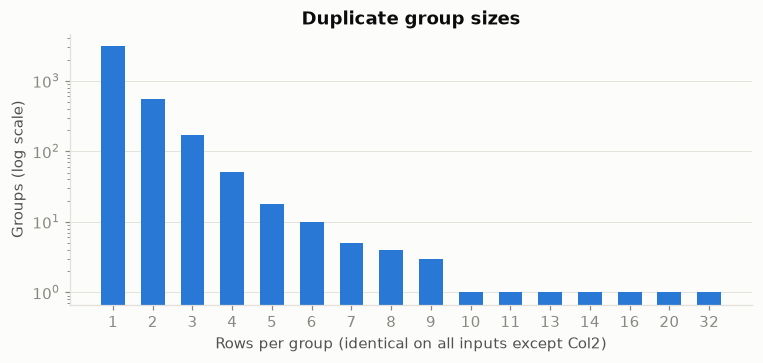

In [17]:
display(pd.Series(report("eda/duplicates_summary.json")).to_frame("value"))
sizes = report("eda/duplicate_group_sizes.csv")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(sizes["group_size"].astype(str), sizes["groups"], color="#2a78d6", width=0.6)
ax.set_yscale("log")
ax.set_xlabel("Rows per group (identical on all inputs except Col2)")
ax.set_ylabel("Groups (log scale)")
ax.set_title("Duplicate group sizes")
ax.grid(axis="x", visible=False)
plt.show()

In [18]:
display(report("eda/conflict_groups.csv"))
pd.DataFrame(report("eda/accuracy_ceiling.json")).T

,group_id,rows,Col1,Col3,Col4,Col5,Col6,Col7,Category_1,Category_2,Category_3,Category_4,Category_5,Category_6
0,256,5,Word42 Word43 Word5,1510.0,Word562,2018-07,Word563 Word580 Word581 Word232,NoDoc,3,2,0,0,0,0


,ceiling_accuracy,key_columns,mixed_groups,rows_in_mixed_groups
text_amount_doc,0.999623,"[Col1, Col4, Col6, Col3, Col7]",1,5
text_only,0.996044,"[Col1, Col4, Col6]",14,71


**Takeaway.**

- **1,364 training rows (26%) repeat another row on every input except the invoice number.** One group holds 32 copies. A random split would put copies on both sides, so the model would be graded on rows it had memorized. Every split and every cross-validation fold is therefore **grouped**: rows that are identical on every model input (with the date reduced to its month) always land on the same side. A random-split comparison in notebook 03 measures how much a random split would have inflated the scores.
- Duplicates stay in training. They reflect how often each pattern really occurs in the ledger.
- **The data is almost perfectly consistent.** Only one group (5 identical rows) carries two labels (3 Category_1, 2 Category_2). Rows with identical vendor, description, and account cap accuracy at 0.996; adding amount and document flag raises the cap to 0.9996. Remaining model errors will come from generalization, not contradictory labels.

## 11. The rare classes up close

In [19]:
report("eda/rare_class_rows.csv")

,row_id,class,Col1,Col2,Col3,Col4,Col5,Col6,Col7
0,168,Category_3,Word137 Word138 Word7,UZZE5868,1680.00,Word905 Word794,2018-08,Word563 Word359,NoDoc
1,1828,Category_3,Word137 Word138 Word7,ARBG5026,1680.00,Word984 Word835 Word905 Word791,2018-05,Word563 Word359,NoDoc
2,2346,Category_3,Word137 Word138 Word7,ICMH5026,1680.00,Word984 Word835 Word905 Word791,2018-05,Word563 Word359,NoDoc
3,2362,Category_3,Word137 Word138 Word7,DFEE5269,1680.00,Word834 Word835 Word905 Word791,2018-06,Word563 Word359,NoDoc
4,3076,Category_3,Word137 Word138 Word7,ERPW5269,1680.00,Word834 Word835 Word905 Word791,2018-06,Word563 Word359,NoDoc
5,3196,Category_3,Word137 Word138 Word7,XTHS6197,1680.00,Word905 Word794,2018-09,Word563 Word359,NoDoc
6,3531,Category_3,Word137 Word138 Word7,PCBP5026,1680.00,Word984 Word835 Word905 Word791,2018-05,Word563 Word359,NoDoc
7,3533,Category_3,Word137 Word138 Word7,ELEL5026,1680.00,Word984 Word835 Word905 Word791,2018-05,Word563 Word359,NoDoc
8,3687,Category_3,Word137 Word138 Word7,MBDJ6197,1680.00,Word905 Word794,2018-09,Word563 Word359,NoDoc
9,4232,Category_3,Word137 Word138 Word7,YRGS5026,1680.00,Word984 Word835 Word905 Word791,2018-05,Word563 Word359,NoDoc


**Takeaway.** The rare classes are tight patterns, not noise:

- **Category_3**: 15 of 20 rows come from vendor `Word137 Word138 Word7` at exactly 1,680.
- **Category_4**: 10 of 14 from vendor `Word101 Word102 Word103 Word7` with `Doc3`; 3 more are that same 1,680 vendor in 2017-12 and 2018-01.
- **Category_6**: 3 rows are the same 1,680 vendor in 2018-04.
- **Category_5**: both rows are vendor `Word324 Word4` with negative amounts in 2018-10.

One vendor at one amount spans three rare classes, separated only by description tokens and **posting month**. That is why the period feature stays (dropping it cuts Category_4 recall from 0.55 to 0.38 in the benchmark ablation), and why the tree model may build leaves from as few as 1 or 2 rows.

## Summary: what the data decided

| Finding | Decision |
|---|---|
| 11 label spellings of 6 classes | One fixed normalization rule, also applied to uploads |
| 26% of rows duplicate another except for Col2 | Grouped splits and grouped cross-validation everywhere |
| Col2 is a corrupted identifier | Dropped from the model, kept for display |
| Text columns carry the label; tokens reused across columns | Per-column TF-IDF plus whole-value and pair one-hots |
| Heavy-tailed amounts, meaningful sign, recurring round values | Signed log, negative and round flags, no outlier removal |
| Monthly periods, rare classes clustered in time | Clipped period index; out-of-time validation |
| 88% majority class, four tiny classes | Accuracy plus macro F1; Category_5 reported separately |

Next: `02_preprocessing.ipynb` shows each transformation, and `03_modeling.ipynb` the model comparison, tuning, and evaluation.